# CCA 1: Effect of Chi-Square Feature Selection on Traditional Machine Learning Models for Fake News Classification

**Dataset:** existing `Fake.csv` and `True.csv` files  
**Task:** binary classification — Fake (0) vs Real (1)  
**Models:** Logistic Regression, Multinomial Naive Bayes, Linear SVM

This notebook demonstrates text preprocessing, TF-IDF feature extraction, numerical feature vectors, supervised classification, model evaluation and graphical comparisons.

> These models learn dataset-associated patterns. They do not independently verify claims against external evidence.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


## Load the existing datasets


In [2]:
from pathlib import Path

# Dataset folder path
dataset_path = Path(
    r"C:\Users\sahil\OneDrive\Desktop\CCA Misinformation detection using Feature selection\dataset"
)

# Load CSV files
fake_path = dataset_path / "Fake.csv"
true_path = dataset_path / "True.csv"

fake_df = pd.read_csv(fake_path)
true_df = pd.read_csv(true_path)

# Display dataset information
print("Fake Dataset Shape:", fake_df.shape)
print("True Dataset Shape:", true_df.shape)

print("\nFake News Dataset:")
display(fake_df.head())

print("\nReal News Dataset:")
display(true_df.head())

Fake Dataset Shape: (23481, 4)
True Dataset Shape: (21417, 4)

Fake News Dataset:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"



Real News Dataset:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


## Prepare the data
Combine article title and body text. Labels are `0 = Fake` and `1 = Real`. Remove empty articles and exact duplicate content.

In [3]:
fake_df, true_df = fake_df.copy(), true_df.copy()
fake_df["label"], true_df["label"] = 0, 1
df = pd.concat([fake_df, true_df], ignore_index=True, sort=False)
for col in ["title", "text"]:
    if col not in df.columns: df[col] = ""
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)
df["content"] = (df["title"].str.strip() + " " + df["text"].str.strip()).str.strip()
df = df[df["content"].str.len() > 0].copy()
before = len(df)
df = df.drop_duplicates(subset=["content"]).reset_index(drop=True)
print(f"Usable articles: {len(df):,}; duplicate articles removed: {before-len(df):,}")
display(df[["title", "content", "label"]].head())

Usable articles: 39,103; duplicate articles removed: 5,795


,title,content,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump Sends Out Embarrassing New Year’s...,0
1,Drunk Bragging Trump Staffer Started Russian ...,Drunk Bragging Trump Staffer Started Russian C...,0
2,Sheriff David Clarke Becomes An Internet Joke...,Sheriff David Clarke Becomes An Internet Joke ...,0
3,Trump Is So Obsessed He Even Has Obama’s Name...,Trump Is So Obsessed He Even Has Obama’s Name ...,0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis Just Called Out Donald Trump Duri...,0


## Visualize the class distribution

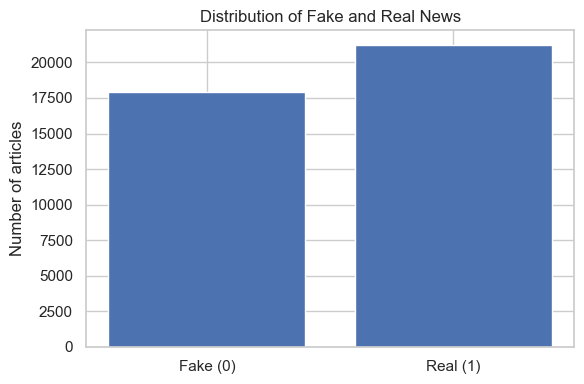

In [4]:
counts = df["label"].value_counts().reindex([0, 1], fill_value=0)
plt.figure(figsize=(6, 4))
plt.bar(["Fake (0)", "Real (1)"], counts.values)
plt.title("Distribution of Fake and Real News")
plt.ylabel("Number of articles")
plt.tight_layout(); plt.show()

## Split the data and extract TF-IDF features
Use a stratified 80/20 train/test split.

In [5]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["content"].astype(str), df["label"].astype(int),
    test_size=0.20, random_state=RANDOM_STATE, stratify=df["label"].astype(int)
)
vectorizer = TfidfVectorizer(max_features=5000, stop_words="english",
                             ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)
print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])
print("TF-IDF feature dimensions:", X_train.shape[1])

Training samples: 31282
Test samples: 7821
TF-IDF feature dimensions: 5000


## Feature selection using Chi-Square (χ²)

TF-IDF converts article text into numerical features. Chi-Square ranks these features by their association with the Fake/Real labels. We select up to 3,000 highest-scoring features. The selector is fitted only on the training set to prevent data leakage, then applied to the test set.


In [6]:
# Select up to 3,000 informative TF-IDF features
K_BEST = min(3000, X_train.shape[1])
selector = SelectKBest(score_func=chi2, k=K_BEST)

# Fit only on training data; transform both training and test data
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

print("Features before selection:", X_train.shape[1])
print("Features after selection:", X_train_selected.shape[1])


Features before selection: 5000
Features after selection: 3000


## Train all three models with and without Chi-Square

In [7]:
import time

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

results = []
predictions = {}

for name, model in models.items():

    # Experiment A: Without Chi-Square
    start = time.time()

    model.fit(X_train, y_train)
    pred_without = model.predict(X_test)

    time_without = time.time() - start

    results.append({
        "Model": name,
        "Feature Selection": "Without Chi-Square",
        "Accuracy": accuracy_score(y_test, pred_without),
        "Precision": precision_score(y_test, pred_without, average="macro"),
        "Recall": recall_score(y_test, pred_without, average="macro"),
        "F1 Score": f1_score(y_test, pred_without, average="macro"),
        "Training Time": time_without
    })

    predictions[name + " - Without Chi-Square"] = pred_without

    # Experiment B: With Chi-Square
    start = time.time()

    selected_model = type(model)(**model.get_params())
    selected_model.fit(X_train_selected, y_train)
    pred_with = selected_model.predict(X_test_selected)

    time_with = time.time() - start

    results.append({
        "Model": name,
        "Feature Selection": "With Chi-Square",
        "Accuracy": accuracy_score(y_test, pred_with),
        "Precision": precision_score(y_test, pred_with, average="macro"),
        "Recall": recall_score(y_test, pred_with, average="macro"),
        "F1 Score": f1_score(y_test, pred_with, average="macro"),
        "Training Time": time_with
    })

    predictions[name + " - With Chi-Square"] = pred_with

print("All six experiments completed!")

All six experiments completed!


## Display the performance comparison table

In [8]:
comparison_df = pd.DataFrame(results)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Training Time": "{:.4f}"
    })
)

,Model,Feature Selection,Accuracy,Precision,Recall,F1 Score,Training Time
0,Logistic Regression,Without Chi-Square,0.9925,0.9925,0.9923,0.9924,1.2918
1,Logistic Regression,With Chi-Square,0.9917,0.9918,0.9915,0.9916,1.2168
2,Multinomial Naive Bayes,Without Chi-Square,0.9519,0.9517,0.9514,0.9516,0.0566
3,Multinomial Naive Bayes,With Chi-Square,0.9540,0.9538,0.9534,0.9536,0.0355
4,Linear SVM,Without Chi-Square,0.9967,0.9968,0.9965,0.9967,0.6573
5,Linear SVM,With Chi-Square,0.9962,0.9962,0.9960,0.9961,0.4199


## Generate comparison graphs

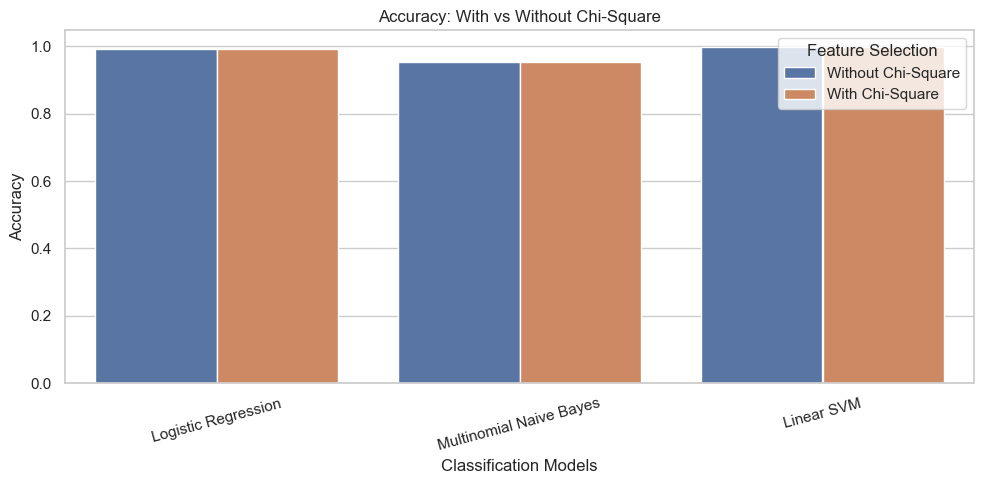

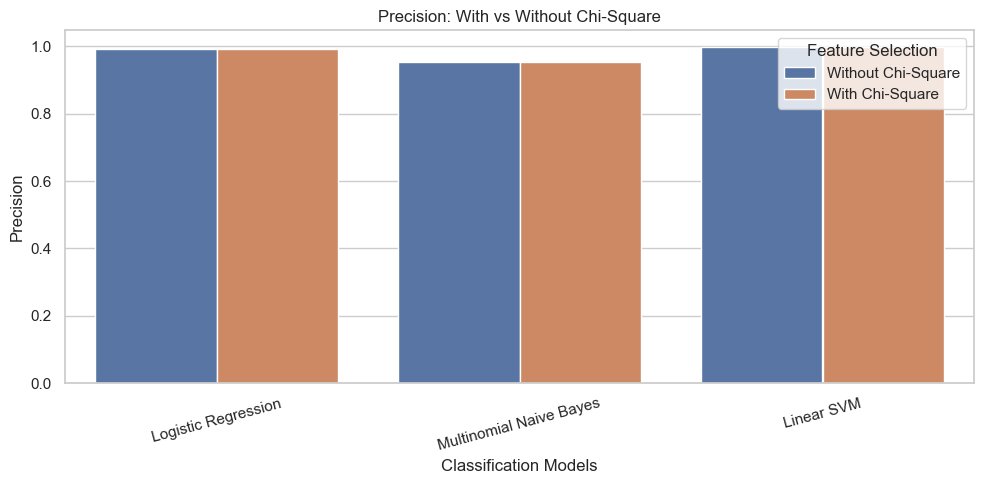

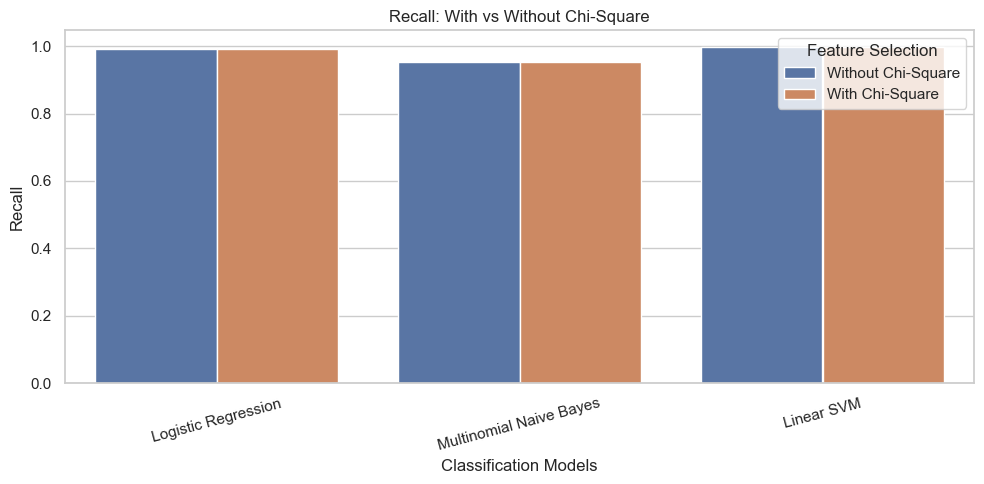

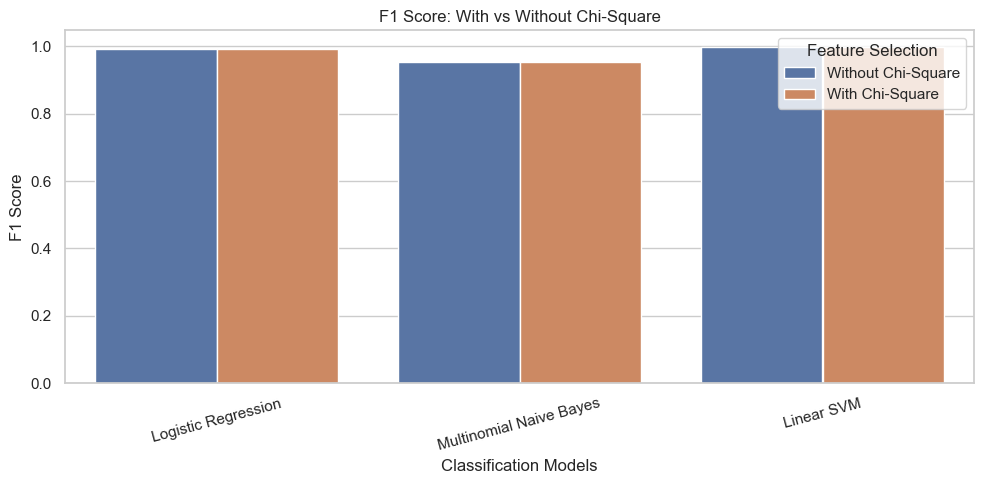

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=comparison_df,
        x="Model",
        y=metric,
        hue="Feature Selection"
    )

    plt.title(f"{metric}: With vs Without Chi-Square")
    plt.ylabel(metric)
    plt.xlabel("Classification Models")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## Compare confusion matrices

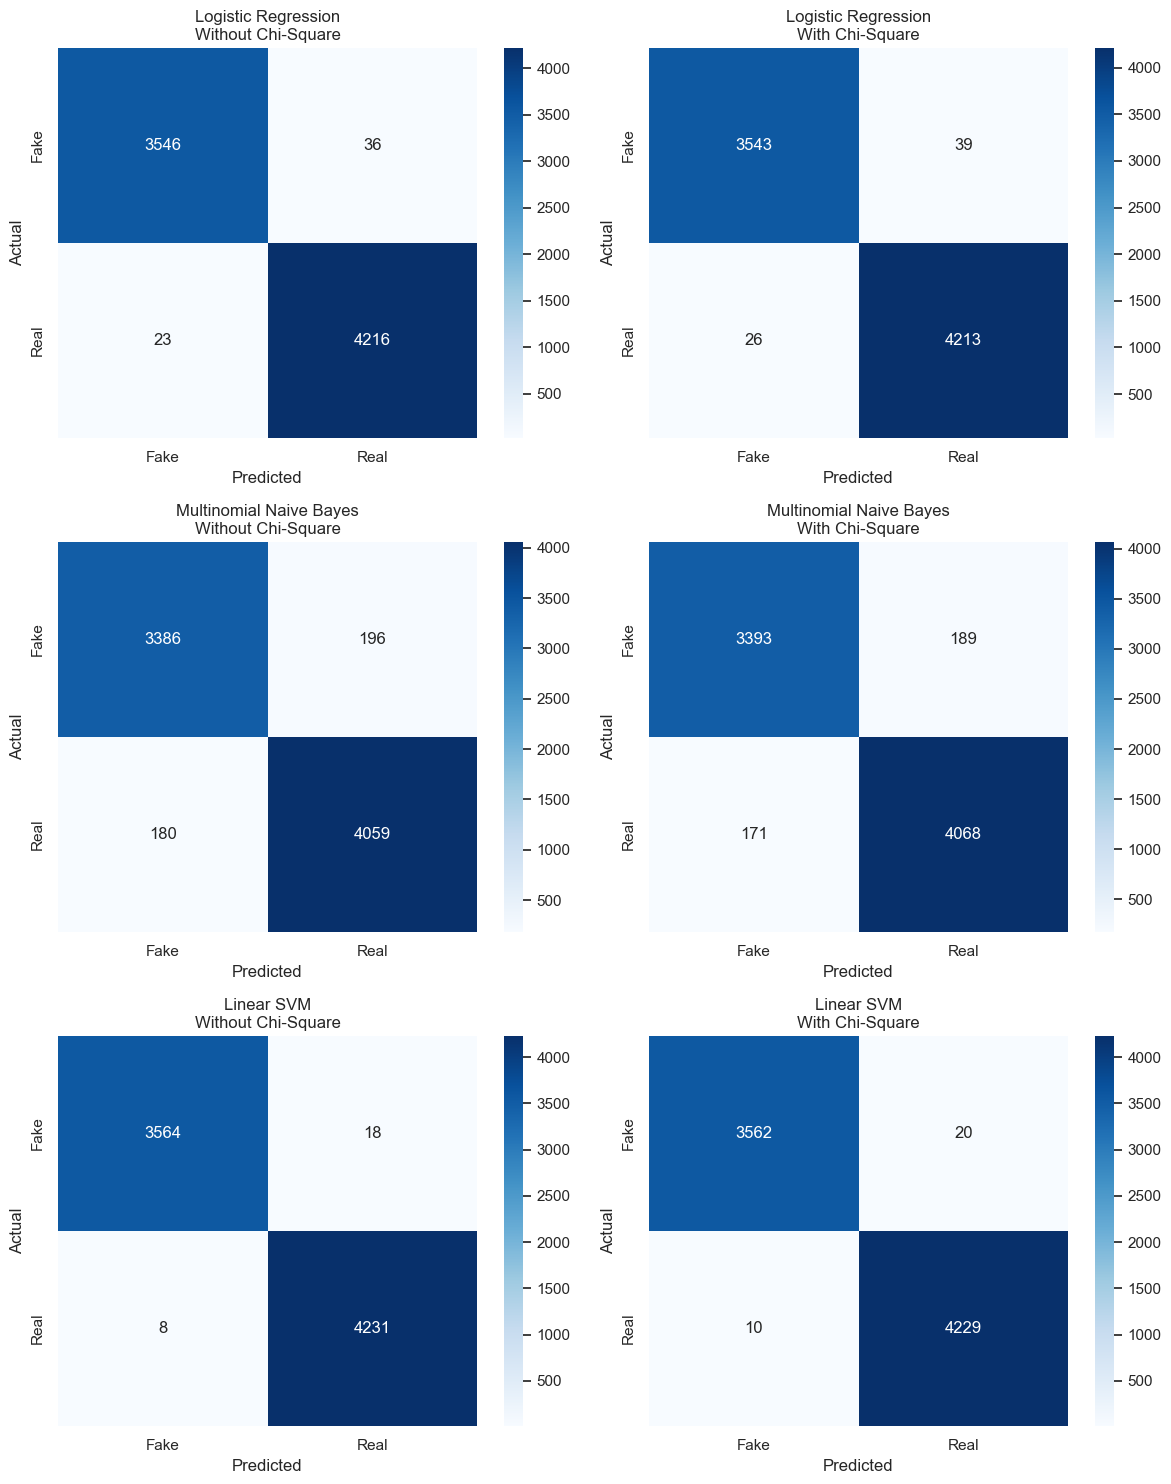

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for i, model_name in enumerate(models.keys()):

    for j, method in enumerate(
        ["Without Chi-Square", "With Chi-Square"]
    ):

        key = model_name + " - " + method
        pred = predictions[key]

        cm = confusion_matrix(y_test, pred)

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=["Fake", "Real"],
            yticklabels=["Fake", "Real"],
            ax=axes[i, j]
        )

        axes[i, j].set_title(model_name + "\n" + method)
        axes[i, j].set_xlabel("Predicted")
        axes[i, j].set_ylabel("Actual")

plt.tight_layout()
plt.show()

## Visualize the selected features

The chart shows the 15 selected terms with the highest Chi-Square scores. A high score indicates association with the training labels; it does not prove that a term is inherently fake or true.


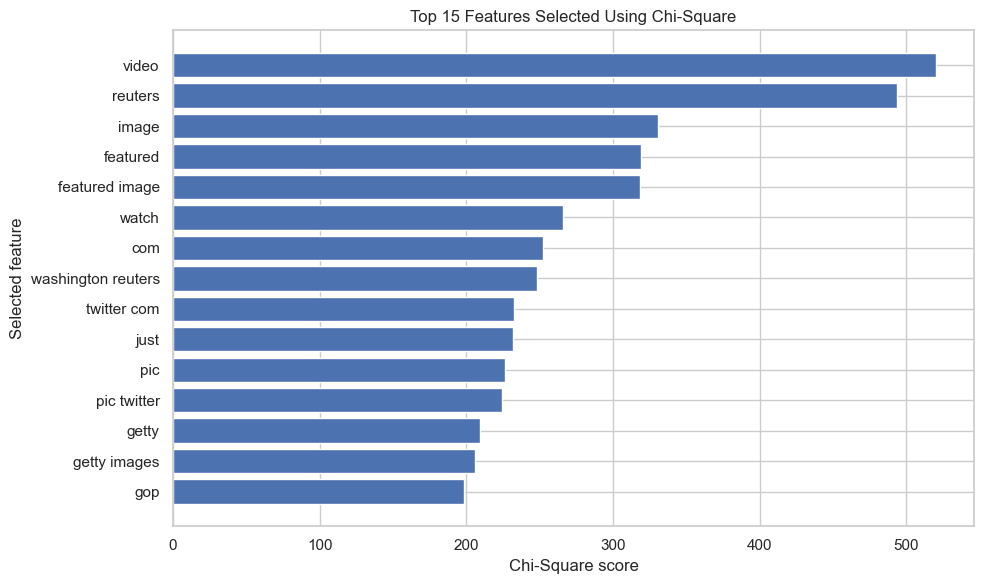

In [11]:
feature_names = np.array(vectorizer.get_feature_names_out())
selected_indices = selector.get_support(indices=True)
selected_names = feature_names[selected_indices]
selected_scores = selector.scores_[selected_indices]
top_n = min(15, len(selected_indices))
top_positions = np.argsort(selected_scores)[-top_n:]

plt.figure(figsize=(10, 6))
plt.barh(selected_names[top_positions], selected_scores[top_positions])
plt.title("Top 15 Features Selected Using Chi-Square")
plt.xlabel("Chi-Square score")
plt.ylabel("Selected feature")
plt.tight_layout()
plt.show()


## Train three pattern-recognition models
All three models use identical TF-IDF features and the same test set for a fair comparison.

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=RANDOM_STATE)
}
fitted_models, predictions = {}, {}
for name, model in models.items():
    print("Training", name)
    model.fit(X_train_selected, y_train)
    fitted_models[name] = model
    predictions[name] = model.predict(X_test_selected)
print("All models trained.")

Training Logistic Regression
Training Multinomial Naive Bayes
Training Linear SVM
All models trained.


## Evaluate model performance
Macro-averaged precision, recall and F1-score give equal weight to both classes.

In [13]:
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "Macro F1-score": f1_score(y_test, pred, average="macro", zero_division=0)
    })
results_df = pd.DataFrame(rows).sort_values("Macro F1-score", ascending=False).reset_index(drop=True)
display(results_df.style.format({c: "{:.4f}" for c in results_df.columns if c != "Model"}))

,Model,Accuracy,Precision (macro),Recall (macro),Macro F1-score
0,Linear SVM,0.9962,0.9962,0.9960,0.9961
1,Logistic Regression,0.9917,0.9918,0.9915,0.9916
2,Multinomial Naive Bayes,0.9540,0.9538,0.9534,0.9536


## Graph: compare the three models

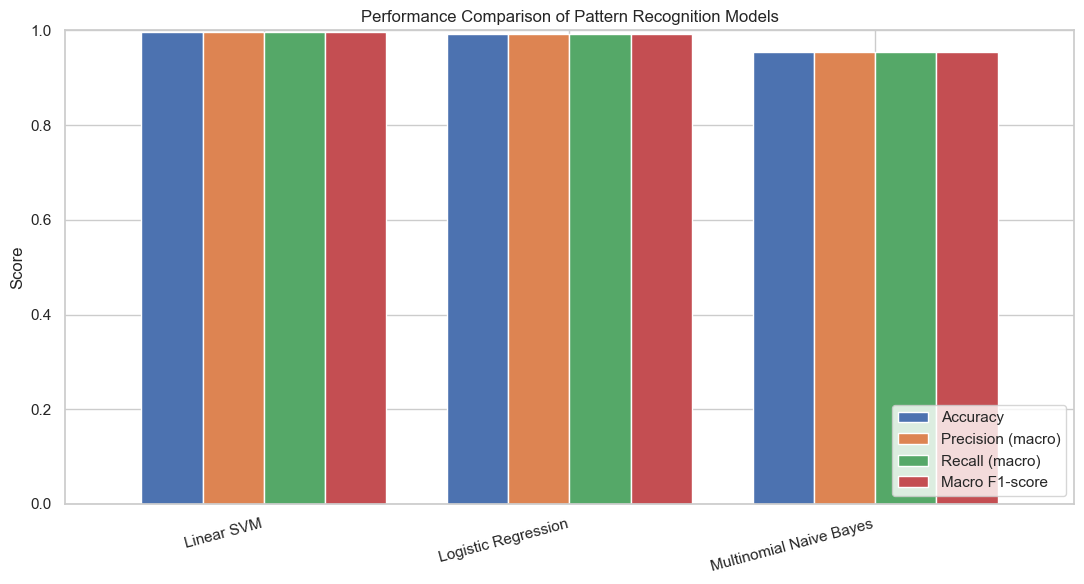

In [14]:
metrics = ["Accuracy", "Precision (macro)", "Recall (macro)", "Macro F1-score"]
ax = results_df.set_index("Model")[metrics].plot(kind="bar", figsize=(11, 6), ylim=(0, 1), width=0.8)
ax.set_title("Performance Comparison of Pattern Recognition Models")
ax.set_ylabel("Score"); ax.set_xlabel("")
plt.xticks(rotation=15, ha="right"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

## Confusion matrices
Rows are actual labels and columns are predicted labels.

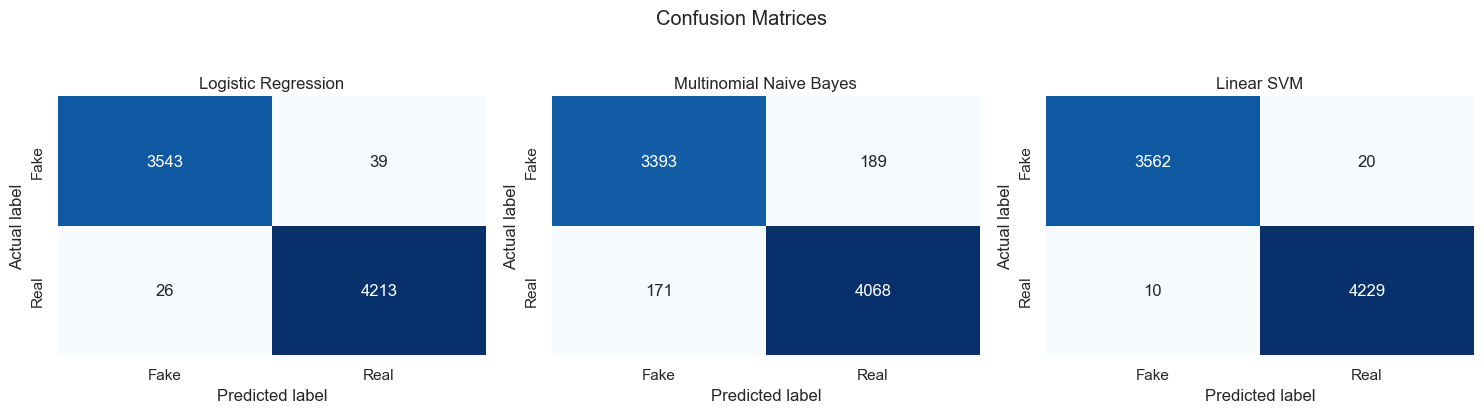

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"], ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label")
plt.suptitle("Confusion Matrices", y=1.03); plt.tight_layout(); plt.show()

## Classification reports

In [16]:
for name, pred in predictions.items():
    print("\n" + "=" * 65 + "\n" + name)
    print(classification_report(y_test, pred, labels=[0, 1],
                                target_names=["Fake", "Real"], digits=4, zero_division=0))


Logistic Regression
              precision    recall  f1-score   support

        Fake     0.9927    0.9891    0.9909      3582
        Real     0.9908    0.9939    0.9923      4239

    accuracy                         0.9917      7821
   macro avg     0.9918    0.9915    0.9916      7821
weighted avg     0.9917    0.9917    0.9917      7821


Multinomial Naive Bayes
              precision    recall  f1-score   support

        Fake     0.9520    0.9472    0.9496      3582
        Real     0.9556    0.9597    0.9576      4239

    accuracy                         0.9540      7821
   macro avg     0.9538    0.9534    0.9536      7821
weighted avg     0.9540    0.9540    0.9540      7821


Linear SVM
              precision    recall  f1-score   support

        Fake     0.9972    0.9944    0.9958      3582
        Real     0.9953    0.9976    0.9965      4239

    accuracy                         0.9962      7821
   macro avg     0.9962    0.9960    0.9961      7821
weighted avg    

## Visualize informative terms from Logistic Regression
The coefficient signs show terms associated with each label in this dataset only. They are not universal indicators of truth or falsehood.

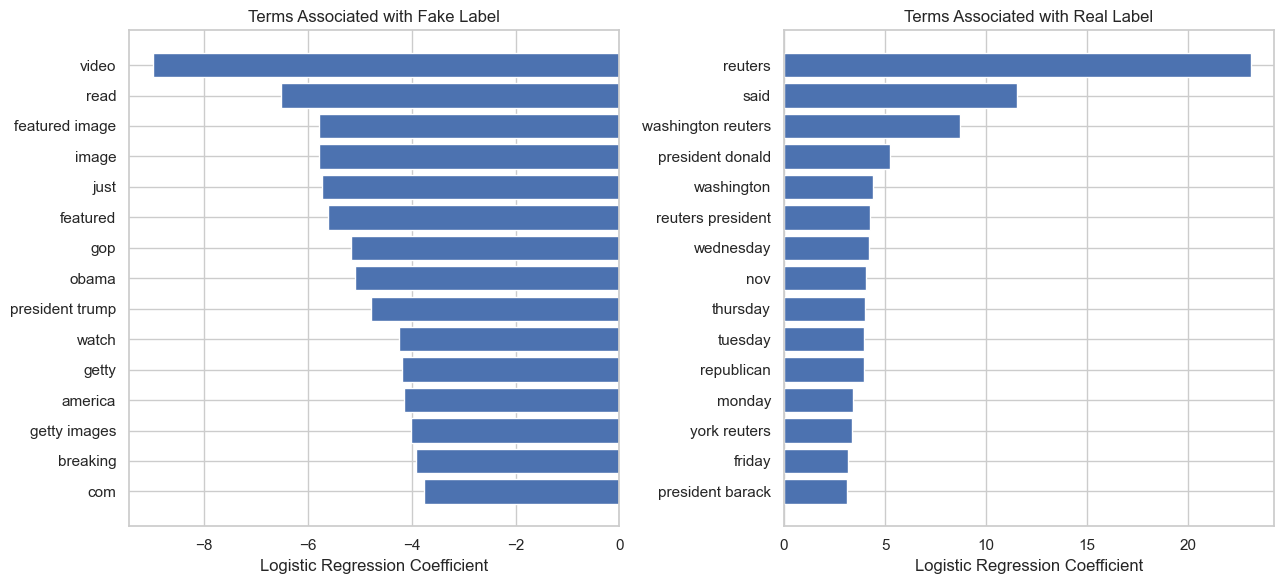

In [18]:
# Get the selected feature names
selected_indices = selector.get_support(indices=True)

feature_names = np.array(
    vectorizer.get_feature_names_out()
)[selected_indices]

# Get Logistic Regression coefficients
coef = fitted_models["Logistic Regression"].coef_[0]

# Find the strongest negative and positive coefficients
fake_idx = np.argsort(coef)[:15]
real_idx = np.argsort(coef)[-15:][::-1]

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Fake-associated terms
axes[0].barh(
    feature_names[fake_idx][::-1],
    coef[fake_idx][::-1]
)

axes[0].set_title("Terms Associated with Fake Label")
axes[0].set_xlabel("Logistic Regression Coefficient")

# Real-associated terms
axes[1].barh(
    feature_names[real_idx][::-1],
    coef[real_idx][::-1]
)

axes[1].set_title("Terms Associated with Real Label")
axes[1].set_xlabel("Logistic Regression Coefficient")

plt.tight_layout()
plt.show()

In [19]:
results_dir = Path("cca_results")
results_dir.mkdir(exist_ok=True)
results_df.to_csv(results_dir / "model_comparison.csv", index=False)
report_rows = []
for name, pred in predictions.items():
    report = classification_report(y_test, pred, labels=[0, 1], target_names=["Fake", "Real"],
                                   output_dict=True, zero_division=0)
    for label, values in report.items():
        if isinstance(values, dict): report_rows.append({"Model": name, "Class": label, **values})
pd.DataFrame(report_rows).to_csv(results_dir / "classification_reports.csv", index=False)
print("Saved results to:", results_dir.resolve())
display(results_df)

Saved results to: C:\Users\sahil\OneDrive\Desktop\CCA Misinformation detection using Feature selection\cca_results


,Model,Accuracy,Precision (macro),Recall (macro),Macro F1-score
0,Linear SVM,0.996164,0.996247,0.996029,0.996136
1,Logistic Regression,0.991689,0.991771,0.991489,0.991628
2,Multinomial Naive Bayes,0.953970,0.953811,0.953448,0.953625
